In [1]:
from pathlib import Path

import harmonypy as hm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

DIR_PROCESADOS = Path("../data/processed")
DIR_FIGURAS = Path("../results/figuras")
DIR_TABLAS = Path("../results/tablas")

adata = sc.read_h5ad(DIR_PROCESADOS / "02_qc.h5ad")
adata


AnnData object with n_obs × n_vars = 20369 × 21761
    obs: 'donante', 'condicion', 'muestra', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'atipico', 'atipico_mt', 'pasa_qc', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'muestra_colors', 'scrublet'
    layers: None (.X)

In [2]:
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [3]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="muestra")
adata.var["highly_variable"].sum()

np.int64(2000)

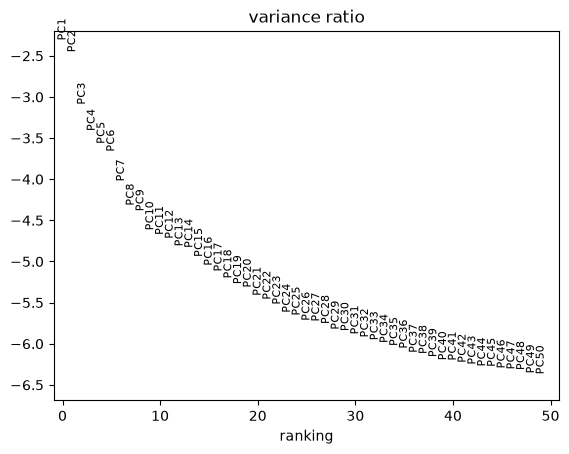

In [4]:
sc.pp.pca(adata, n_comps=50, mask_var="highly_variable")

sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True, show=False)
plt.savefig(DIR_FIGURAS / "pca_varianza.png", dpi=150, bbox_inches="tight")

In [5]:
ho = hm.run_harmony(adata.obsm["X_pca"], adata.obs, "muestra", random_state=0)
z = np.asarray(ho.Z_corr)
assert z.shape == adata.obsm["X_pca"].shape, z.shape
adata.obsm["X_pca_harmony"] = z

2026-10-30 17:51:58,300 - harmonypy - INFO - Running Harmony
2026-10-30 17:51:58,301 - harmonypy - INFO -   Parameters:
2026-10-30 17:51:58,301 - harmonypy - INFO -     max_iter_harmony: 10
2026-10-30 17:51:58,302 - harmonypy - INFO -     max_iter_kmeans: 4
2026-10-30 17:51:58,302 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-10-30 17:51:58,303 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-10-30 17:51:58,303 - harmonypy - INFO -     nclust: 100
2026-10-30 17:51:58,303 - harmonypy - INFO -     block_size: 0.05
2026-10-30 17:51:58,304 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-10-30 17:51:58,305 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
2026-10-30 17:51:58,305 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-10-30 17:51:58,306 - harmonypy - INFO -     verbose: True
2026-10-30 17:51:58,306 - harmonypy - INFO -     random_state: 0
2026-10-30 17:51:58,306 - harmonypy - INFO -   Data: 50 PCs × 20369 cells
2026-

In [6]:
sc.pp.neighbors(adata, use_rep="X_pca_harmony", n_pcs=30)
sc.tl.umap(adata, random_state=0)
sc.tl.leiden(adata, resolution=0.5, flavor="igraph", n_iterations=2,
             key_added="leiden", random_state=0)
adata.obs["leiden"].value_counts().sort_index()

leiden
0     1544
1     3314
2      490
3      286
4     1581
5     3103
6      559
7     2504
8     1382
9       22
10      11
11    1504
12      35
13       7
14      10
15     662
16     916
17     296
18     299
19     513
20     566
21     330
22     435
Name: count, dtype: int64

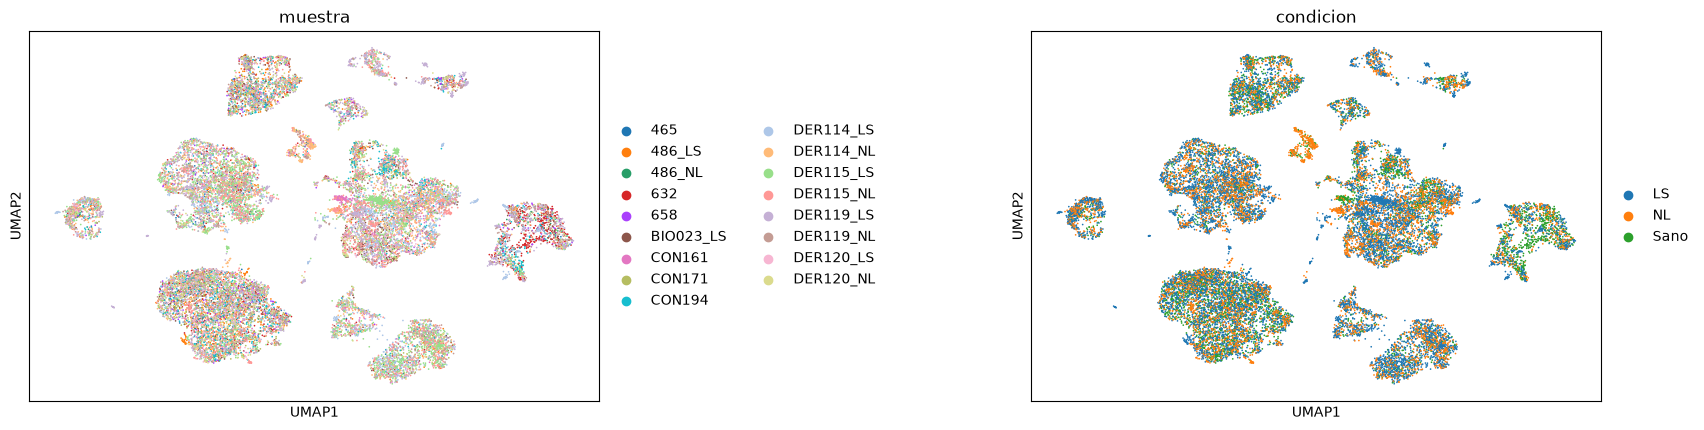

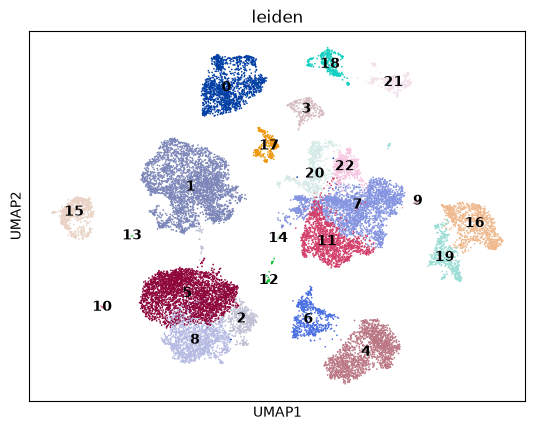

In [13]:
sc.pl.umap(adata, color=["muestra", "condicion"], ncols=2, wspace=0.6, show=False)
plt.savefig(DIR_FIGURAS / "umap_muestra_condicion.png", dpi=150, bbox_inches="tight")

sc.pl.umap(adata, color="leiden", legend_loc="on data", show=False)
plt.savefig(DIR_FIGURAS / "umap_clusters.png", dpi=150, bbox_inches="tight")

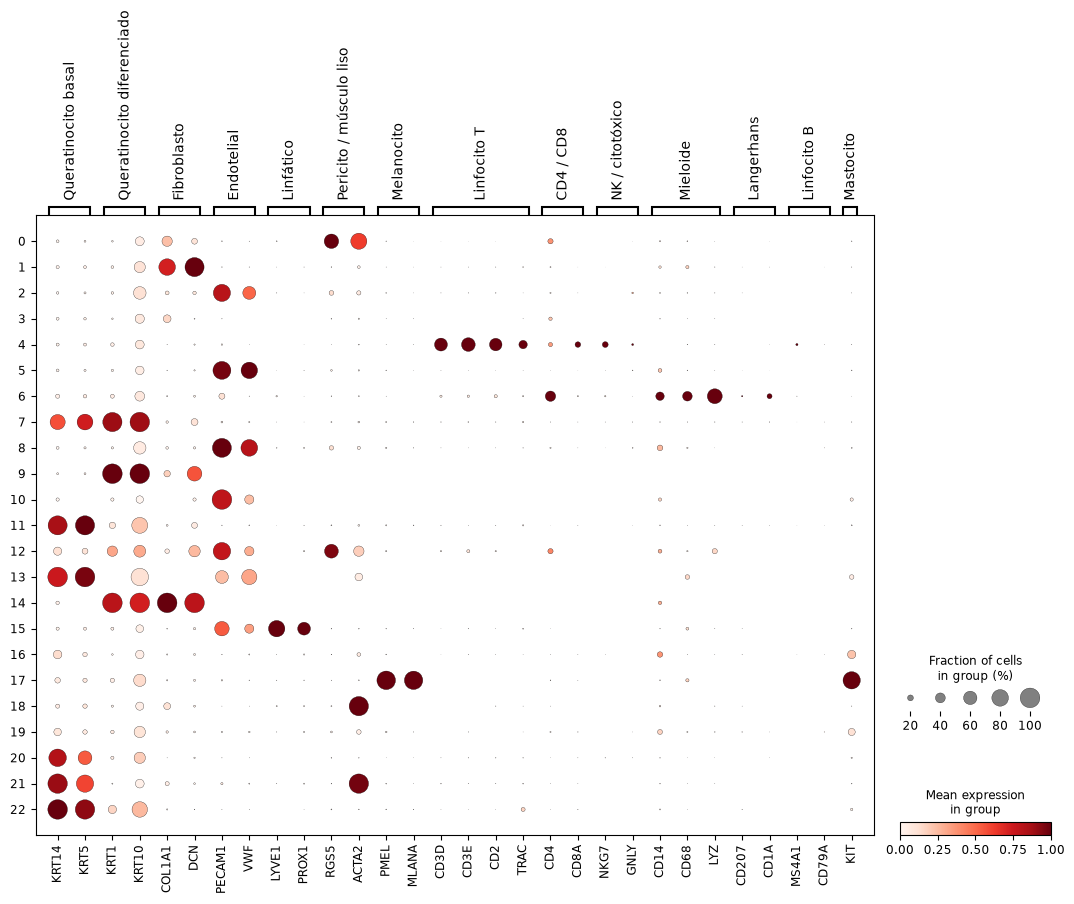

In [8]:
marcadores = {
    "Queratinocito basal": ["KRT14", "KRT5"],
    "Queratinocito diferenciado": ["KRT1", "KRT10"],
    "Fibroblasto": ["COL1A1", "DCN"],
    "Endotelial": ["PECAM1", "VWF"],
    "Linfático": ["LYVE1", "PROX1"],
    "Pericito / músculo liso": ["RGS5", "ACTA2"],
    "Melanocito": ["PMEL", "MLANA"],
    "Linfocito T": ["CD3D", "CD3E", "CD2", "TRAC"],
    "CD4 / CD8": ["CD4", "CD8A"],
    "NK / citotóxico": ["NKG7", "GNLY"],
    "Mieloide": ["CD14", "CD68", "LYZ"],
    "Langerhans": ["CD207", "CD1A"],
    "Linfocito B": ["MS4A1", "CD79A"],
    "Mastocito": ["TPSAB1", "KIT"],
}
marcadores = {k: [g for g in v if g in adata.var_names] for k, v in marcadores.items()}

sc.pl.dotplot(adata, marcadores, groupby="leiden", standard_scale="var", show=False)
plt.savefig(DIR_FIGURAS / "dotplot_marcadores_clusters.png", dpi=150, bbox_inches="tight")

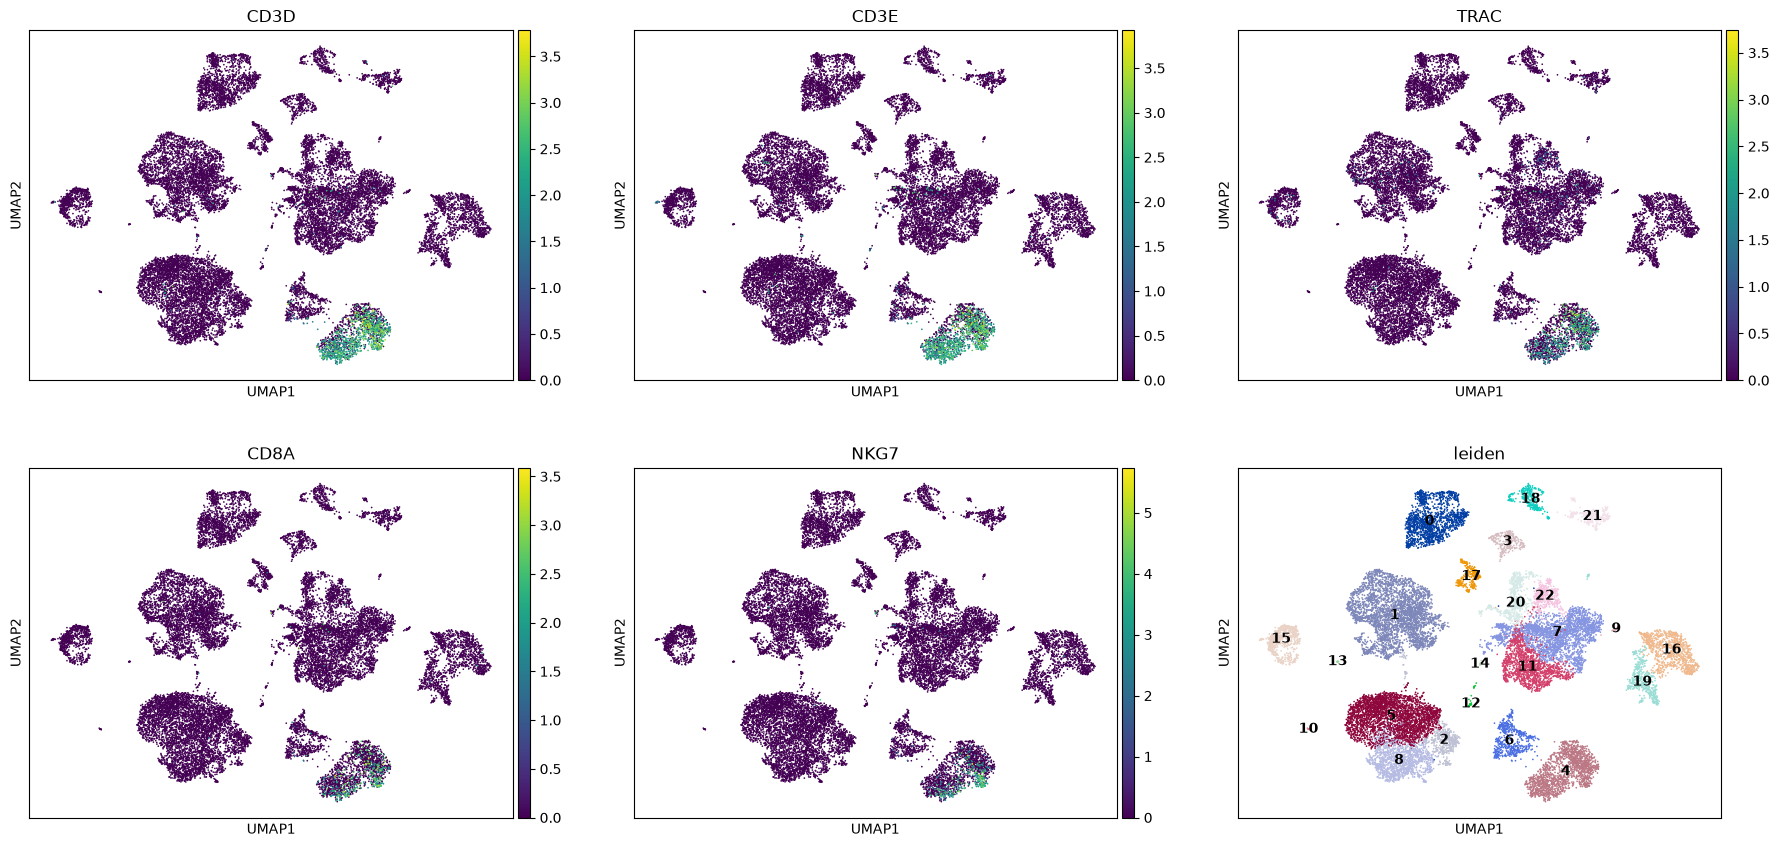

In [9]:
sc.pl.umap(adata, color=["CD3D", "CD3E", "TRAC", "CD8A", "NKG7", "leiden"],
           legend_loc="on data", ncols=3, show=False)
plt.savefig(DIR_FIGURAS / "umap_marcadores_T.png", dpi=150, bbox_inches="tight")

In [14]:
adata.obs["es_T"] = adata.obs["leiden"] == "4"

t_por_muestra = (adata.obs.groupby(["condicion", "donante", "muestra"], observed=True)["es_T"]
                 .agg(celulas="size", T="sum").reset_index())
t_por_muestra["pct_T"] = (100 * t_por_muestra["T"] / t_por_muestra["celulas"]).round(1)
print(t_por_muestra.to_string(index=False))
print(t_por_muestra.groupby("condicion")["T"].agg(["sum", "min", "median", "max"]))
t_por_muestra.to_csv(DIR_TABLAS / "t_por_muestra.csv", index=False)

condicion donante   muestra  celulas   T  pct_T
       LS     486    486_LS     1134  36    3.2
       LS  BIO023 BIO023_LS     1040  27    2.6
       LS  DER114 DER114_LS     2174 321   14.8
       LS  DER115 DER115_LS     3013 458   15.2
       LS  DER119 DER119_LS     2196  85    3.9
       LS  DER120 DER120_LS      378   6    1.6
       NL     486    486_NL      168   0    0.0
       NL  DER114 DER114_NL     1586 110    6.9
       NL  DER115 DER115_NL     2044 214   10.5
       NL  DER119 DER119_NL      920  58    6.3
       NL  DER120 DER120_NL      767  34    4.4
     Sano     465       465      445  32    7.2
     Sano     632       632      916  37    4.0
     Sano     658       658      489   3    0.6
     Sano  CON161    CON161      845  34    4.0
     Sano  CON171    CON171      904  85    9.4
     Sano  CON194    CON194     1350  41    3.0
           sum  min  median  max
condicion                       
LS         933    6    60.5  458
NL         416    0    58.0  214
Sano

In [12]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")

for c in ["3", "16", "19"]:
    df = sc.get.rank_genes_groups_df(adata, group=c).head(15)
    print(f"Cluster {c}:", ", ".join(df["names"]))

Cluster 3: NRXN1, CDH19, SCN7A, GPM6B, PMP22, SPARC, CRYAB, MATN2, CD9, XKR4, PLP1, LGALS1, PRNP, S100B, PCSK2
Cluster 16: KRT19, AQP5, KRT15, SNORC, KRT7, KRT18, SFRP1, SLC12A2, GAPDH, ID4, PDCD4, CLDN4, KRT8, HSPA1B, PPP1R1B
Cluster 19: DCD, SCGB2A2, SCGB1B2P, MUCL1, PIP, SCGB1D2, KRT19, AZGP1, KRT7, KRT18, XBP1, PRR4, SLC12A2, LRRC26, AQP5


In [15]:
anotacion = {
    "0": "Pericito",
    "1": "Fibroblasto",
    "2": "Endotelial",
    "3": "Célula de Schwann",
    "4": "Linfocito T",
    "5": "Endotelial",
    "6": "Mieloide",
    "7": "Queratinocito en diferenciación",
    "8": "Endotelial",
    "9": "Descartar",
    "10": "Descartar",
    "11": "Queratinocito basal",
    "12": "Descartar",
    "13": "Descartar",
    "14": "Descartar",
    "15": "Endotelial linfático",
    "16": "Glándula sudorípara",
    "17": "Melanocito",
    "18": "Músculo liso",
    "19": "Glándula sudorípara",
    "20": "Queratinocito basal",
    "21": "Célula mioepitelial",
    "22": "Queratinocito basal",
}
assert set(anotacion) == set(adata.obs["leiden"].cat.categories)

adata.obs["tipo"] = adata.obs["leiden"].map(anotacion).astype("category")
print(adata.obs["tipo"].value_counts())

adata = adata[adata.obs["tipo"] != "Descartar"].copy()
adata.obs["tipo"] = adata.obs["tipo"].cat.remove_unused_categories()
adata

tipo
Endotelial                         4975
Fibroblasto                        3314
Queratinocito basal                2505
Queratinocito en diferenciación    2504
Linfocito T                        1581
Pericito                           1544
Glándula sudorípara                1429
Endotelial linfático                662
Mieloide                            559
Célula mioepitelial                 330
Músculo liso                        299
Melanocito                          296
Célula de Schwann                   286
Descartar                            85
Name: count, dtype: int64


AnnData object with n_obs × n_vars = 20284 × 21761
    obs: 'donante', 'condicion', 'muestra', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'atipico', 'atipico_mt', 'pasa_qc', 'n_genes', 'doublet_score', 'predicted_doublet', 'leiden', 'es_T', 'tipo'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'muestra_colors', 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'condicion_colors', 'leiden_colors', 'rank_genes_groups'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs

tipo                 Linfocito T  Melanocito
condicion muestra                           
LS        486_LS             3.2         0.0
          BIO023_LS          2.6         0.0
          DER114_LS         15.0         0.0
          DER115_LS         15.2         0.1
          DER119_LS          4.0         0.0
          DER120_LS          1.6         0.0
NL        486_NL             0.0         0.0
          DER114_NL          6.9         9.1
          DER115_NL         10.5         1.6
          DER119_NL          6.3         3.6
          DER120_NL          4.4         0.8
Sano      465                7.2         2.7
          632                4.0         0.7
          658                0.6         0.0
          CON161             4.0         5.2
          CON171             9.4         1.0
          CON194             3.0         0.4

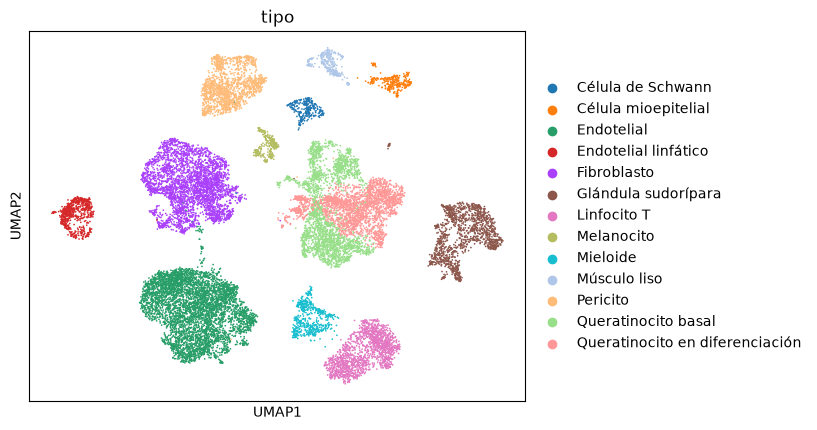

In [16]:
sc.pl.umap(adata, color="tipo", show=False)
plt.savefig(DIR_FIGURAS / "umap_tipos_celulares.png", dpi=150, bbox_inches="tight")

composicion = (pd.crosstab([adata.obs["condicion"], adata.obs["muestra"]],
                           adata.obs["tipo"], normalize="index")
               .mul(100).round(1))
composicion.to_csv(DIR_TABLAS / "composicion_por_muestra.csv")
composicion[["Linfocito T", "Melanocito"]]

In [17]:
adata.write_h5ad(DIR_PROCESADOS / "03_anotado.h5ad")